# 01 · The resistance forecaster (`/forecast`)

**Forecasting Antibiotic Resistance with AI** · Final Year Project · Hamza Afzal (models), Muhammad Ali Mirza (data and evolution), Suleman Saleh (platform)

This notebook trains the forecaster the website serves on `/forecast`, run `D3_forecaster_deploy_v7`, **step by step with the project's own code** (`experiments/run.py` and `experiments/lib/`), and checks at the end that it reproduces the published run exactly.

| | |
|---|---|
| Input | antibiotic, organism (genus, species, taxon ID), MIC value and sign |
| Output | probability of resistance and a Resistant / Susceptible call |
| Algorithm | LightGBM (gradient-boosted trees) with a monotone MIC effect, isotonic calibration |
| Data | the complete BV-BRC AMR export, cleaning v7: 7.85 M rows, 439,542 genomes |
| Split | **by genome**: no genome is in both training and test |

The code of each library function used is printed where it is first used, so every step can be read here. Run time on an 8 GB laptop: about 6 minutes.

In [1]:
import os, sys, json, inspect, time
import numpy as np
import pandas as pd

ROOT = os.path.abspath('..')                      # the project folder (this notebook is in notebooks/)
sys.path.insert(0, os.path.join(ROOT, 'experiments'))

import run as pipeline                            # experiments/run.py
import algorithms                                 # experiments/algorithms/
from lib import data_prep, encoders, metrics, splits

def show(fn):
    """Print a function's source code from the project."""
    print(inspect.getsource(fn))

print('project:', ROOT)

project: C:\Users\HP\OneDrive - Higher Education Commission\Desktop\Final Year Project\FYP2\FYP1


## 1. The configuration

Every model in the project is defined by a small JSON config in `experiments/configs/`. This is the one behind the served forecaster.

In [2]:
cfg = pipeline.load_config(os.path.join(ROOT, 'experiments', 'configs', 'D3_forecaster_deploy_v7.json'))
print(json.dumps({k: cfg[k] for k in ['data', 'split', 'features', 'model', 'calibration', 'threshold']}, indent=2))

{
  "data": {
    "taxon_level": "species",
    "source": "amr_full"
  },
  "split": {
    "strategy": "grouped",
    "test_size": 0.2,
    "seed": 42
  },
  "features": {
    "target_encoding": "oof"
  },
  "model": {
    "type": "lightgbm",
    "monotone_on": [
      "mic_value",
      "mic_log"
    ]
  },
  "calibration": {
    "method": "isotonic"
  },
  "threshold": {
    "strategy": "vme_constrained",
    "vme_budget": 0.1
  }
}


## 2. Data: the cleaned BV-BRC export

`data_prep.get_clean()` (Ali's cleaning, version v7) reads the complete export of 17.6 M BV-BRC AMR records, keeps rows with a usable phenotype, normalises antibiotic names, reads Genome IDs as **text** (as numbers, `195.304` and `195.3040` merge) and stops reading disk-diffusion zone sizes (mm) as MIC values. The result is cached, so this takes seconds after the first run.

In [3]:
t0 = time.time()
dcfg = cfg['data']
df = data_prep.get_clean(source=dcfg.get('source'), normalize_antibiotics=dcfg.get('normalize_antibiotics', True))
df = pipeline.compact(df)                                      # text columns as categories: 1.5 GB -> 0.4 GB
df = pipeline.select_rows(df, dcfg)
df = pipeline.apply_taxon_level(df, dcfg.get('taxon_level', 'strain'))   # strain IDs -> species IDs

lab = df['label_source'] == 'lab'
print(f"rows {len(df):,} | genomes {df['Genome ID'].nunique():,} | antibiotics {df['Antibiotic'].nunique()} | "
      f"resistant {df['target'].mean():.1%} | lab-confirmed rows {lab.sum():,} on {df.loc[lab, 'Genome ID'].nunique():,} genomes "
      f"| {time.time() - t0:.0f} s")
df[['Genome ID', 'Taxon ID', 'genus', 'species', 'Antibiotic', 'drug_class', 'mic_sign', 'mic_value',
    'label_source', 'target']].head()

[data] cache hit: experiments\cache\clean_v7_amr_full_norm.pkl


[data] compacted: 1.50 GB → 0.42 GB


[taxon] species level: 12,545 strain IDs → 247 species IDs


rows 7,847,110 | genomes 439,542 | antibiotics 126 | resistant 28.0% | lab-confirmed rows 649,944 on 87,325 genomes | 7 s


,Genome ID,Taxon ID,genus,species,Antibiotic,drug_class,mic_sign,mic_value,label_source,target
0,1000561.3,287,Pseudomonas,aeruginosa,amikacin,aminoglycoside,unknown,NaN,computational,0
1,1000561.3,287,Pseudomonas,aeruginosa,aztreonam,monobactam,unknown,NaN,computational,0
2,1000561.3,287,Pseudomonas,aeruginosa,cefepime,beta_lactam,unknown,NaN,computational,0
3,1000561.3,287,Pseudomonas,aeruginosa,ceftazidime,beta_lactam,unknown,NaN,computational,0
4,1000561.3,287,Pseudomonas,aeruginosa,ceftazidime/avibactam,beta_lactam,unknown,NaN,computational,0


## 3. Train/test split by genome

Each genome is tested against about 18 antibiotics, so it appears in about 18 rows. A random row split puts the same genome in training and test, and the model scores well by recognising genomes. This is how the original July model reached AUC 0.93; on genomes it had never seen it scored 0.64. Here every split groups rows by genome.

In [4]:
show(splits.make_split)

def make_split(df, strategy='grouped', test_size=0.2, seed=42,
               group_col='Genome ID', holdout_genus=None, cutoff_year=None, verbose=True):
    """Return boolean masks (train, test) over df's rows."""
    y = df['target'].to_numpy()

    if strategy == 'random':
        idx = np.arange(len(df))
        tr, te = train_test_split(idx, test_size=test_size, stratify=y, random_state=seed)

    elif strategy in ('grouped', 'lineage'):
        # 'lineage' is 'grouped' on lineage clusters instead of genomes, so
        # near-identical isolates never straddle the split (run.py adds the
        # lineage_group column; see experiments/genome/lineage.py)
        if strategy == 'lineage':
            group_col = 'lineage_group'
        n_splits = max(2, int(round(1 / test_size)))
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        tr, te = next(splitter.split(df, y, groups=df[group_col].to_numpy()))

    elif strategy == 'species_holdou

In [5]:
scfg = cfg['split']
train_mask, test_mask = splits.make_split(df, strategy=scfg.get('strategy', 'grouped'),
                                          test_size=scfg.get('test_size', 0.2), seed=scfg.get('seed', 42))
shared = set(df.loc[train_mask, 'Genome ID']) & set(df.loc[test_mask, 'Genome ID'])
print(f'train rows {train_mask.sum():,}, test rows {test_mask.sum():,}; genomes on both sides: {len(shared)}')

[split] grouped: train=6,277,678 test=1,569,432 | genomes in both sides: 0


train rows 6,277,678, test rows 1,569,432; genomes on both sides: 0


## 4. Features: resistance rates without leakage

Besides the inputs a user gives (antibiotic, organism, MIC), the model uses three historical resistance rates: per antibiotic, per organism and antibiotic, per genus and antibiotic. On training rows they are computed **out of fold** (each row's rate comes from the other folds, grouped by genome), so a row never sees its own label; test rows use rates from the training data only.

In [6]:
show(encoders.add_rate_features)

def add_rate_features(df, train_mask, mode='oof', folds=None, verbose=True):
    """Attach the three rate features, fitted according to `mode`."""
    out = df.copy()
    if mode == 'none':
        return out, []

    global_mean = float(df.loc[train_mask, 'target'].mean())
    train_idx = np.flatnonzero(train_mask)

    for keys, name, min_count in SPECS:
        if mode == 'leaky':
            # Fitted on everything, including the test rows. This is the bug.
            rate = _rate_map(df, keys, min_count)
            out[name] = _apply_map(df, keys, rate, global_mean)
            continue

        if mode != 'oof':
            raise ValueError(f'unknown encoding mode {mode!r}')

        values = np.full(len(df), np.nan)

        # Training rows: encoded from the other folds only.
        train_frame = df.loc[train_mask]
        for fit_pos, enc_pos in folds:
            rate = _rate_map(train_frame.iloc[fit_pos], keys, min_count)
            rows = train_frame.iloc[enc_pos]
       

In [7]:
fcfg = cfg['features']
folds = splits.inner_folds(df.loc[train_mask], n_splits=fcfg.get('encoding_folds', 5), seed=scfg.get('seed', 42))
df, rate_features = encoders.add_rate_features(df, train_mask, fcfg.get('target_encoding', 'oof'), folds)

features = list(fcfg.get('base', pipeline.BASE_FEATURES)) + rate_features
cat_features = [c for c in algorithms.CAT_FEATURES if c in features]
print(len(features), 'features:', features)

[encode] mode=oof global_mean=0.2804
14 features: ['Taxon ID', 'Antibiotic', 'drug_class', 'genus', 'species', 'mic_sign', 'is_lab_confirmed', 'computational_f1', 'mic_value', 'mic_log', 'has_mic', 'ab_resistance_rate', 'taxon_ab_resistance_rate', 'genus_ab_resistance_rate']


## 5. Training: LightGBM with a monotone MIC effect

A sixth of the training genomes is held back as validation (again grouped by genome) for early stopping. `monotone_on` forces the model's prediction never to fall as the MIC rises, which is what a higher MIC means biologically.

In [8]:
show(algorithms.LightGBMModel.fit)

    def fit(self, X_tr, y_tr, X_val, y_val, cat_features):
        import lightgbm as lgb

        self.features = list(X_tr.columns)
        params = dict(self.params)

        if self.monotone_on:
            params['monotone_constraints'] = [
                1 if f in self.monotone_on else 0 for f in self.features]

        rounds = params.pop('n_estimators', 500)
        train_set = lgb.Dataset(X_tr, label=y_tr, categorical_feature=cat_features)
        val_set = lgb.Dataset(X_val, label=y_val, categorical_feature=cat_features,
                              reference=train_set)
        self.booster = lgb.train(
            params, train_set, num_boost_round=rounds, valid_sets=[val_set],
            callbacks=[lgb.early_stopping(self.EARLY_STOPPING_ROUNDS, verbose=False),
                       lgb.log_evaluation(100)])
        return self



In [9]:
X, y = df[features], df['target'].to_numpy()
X_train_all, X_test = algorithms.align_categories(X.loc[train_mask], X.loc[test_mask], columns=cat_features)
y_train_all, y_test = y[train_mask], y[test_mask]

train_df = df.loc[train_mask].reset_index(drop=True)
fit_pos, val_pos = splits.inner_folds(train_df, n_splits=6, seed=scfg.get('seed', 42))[0]
X_fit, X_val = X_train_all.iloc[fit_pos], X_train_all.iloc[val_pos]
y_fit, y_val = y_train_all[fit_pos], y_train_all[val_pos]

model = algorithms.build_model(cfg['model'])
t0 = time.time()
model.fit(X_fit, y_fit, X_val, y_val, cat_features)
print(f'fit rows {len(X_fit):,}, validation rows {len(X_val):,}; trained in {time.time() - t0:.0f} s;', model.info)

[100]	valid_0's auc: 0.772586


[200]	valid_0's auc: 0.773774


[300]	valid_0's auc: 0.774131


[400]	valid_0's auc: 0.774214


[500]	valid_0's auc: 0.774293


fit rows 5,231,402, validation rows 1,046,276; trained in 179 s; {'kind': 'lightgbm', 'n_trees': 499, 'best_iteration': 499, 'monotone_on': ['mic_value', 'mic_log']}


## 6. Calibration and the decision threshold (on validation genomes, never on test)

Isotonic calibration makes "70%" mean resistant 7 times in 10. The validation genomes are split in two: the calibrator is fitted on one half, and the threshold is chosen on the other as the highest threshold that misses at most 10% of resistant isolates (very major error, VME ≤ 10%).

In [10]:
show(metrics.pick_threshold)

def pick_threshold(y_true, y_score, strategy='fixed', fixed=0.5, vme_budget=0.03):
    """Choose a decision threshold on validation data, never on test."""
    if strategy == 'fixed':
        return float(fixed)

    if strategy == 'maximize_f1':
        prec, rec, thr = precision_recall_curve(y_true, y_score)
        f1 = np.divide(2 * prec * rec, prec + rec,
                       out=np.zeros_like(prec), where=(prec + rec) > 0)
        return float(thr[max(0, int(np.argmax(f1)) - 1)]) if len(thr) else float(fixed)

    if strategy == 'vme_constrained':
        # Highest threshold whose very-major-error rate still fits the budget.
        # VME rises with the threshold, so walk down until it fits.
        for t in np.linspace(0.95, 0.05, 91):
            pred = (y_score >= t).astype(int)
            fn = int(((y_true == 1) & (pred == 0)).sum())
            pos = int((y_true == 1).sum())
            if pos and fn / pos <= vme_budget:
                return float(t)
        return 0.05

In [11]:
val_raw = model.predict_proba(X_val)
val_df = train_df.iloc[val_pos].reset_index(drop=True)
cal_pos, thr_pos = splits.inner_folds(val_df, n_splits=2, seed=scfg.get('seed', 42))[0]
calibrator = metrics.fit_calibrator(y_val[cal_pos], val_raw[cal_pos], cfg['calibration'].get('method', 'isotonic'))
val_score = metrics.apply_calibrator(calibrator, val_raw)

tcfg = cfg['threshold']
threshold = metrics.pick_threshold(y_val[thr_pos], val_score[thr_pos], strategy=tcfg['strategy'],
                                   fixed=tcfg.get('fixed', 0.5), vme_budget=tcfg.get('vme_budget', 0.03))
print(f'calibration: {calibrator["method"]}; threshold chosen on validation: {threshold:.2f}')

calibration: isotonic; threshold chosen on validation: 0.15


## 7. Results on genomes the model never saw

In [12]:
test_raw = model.predict_proba(X_test)
test_score = metrics.apply_calibrator(calibrator, test_raw)
result = metrics.evaluate(y_test, test_score, threshold)
raw = metrics.evaluate(y_test, test_raw, threshold)

test_rows = df.loc[test_mask]
lo, hi = metrics.bootstrap_ci(y_test, test_score, test_rows['Genome ID'].to_numpy(), n_boot=cfg['evaluation'].get('n_boot', 200))
by_source = pipeline.metrics_by_label_source(y_test, test_score, test_rows, threshold, cfg['evaluation'], 'Genome ID')

summary = pd.DataFrame({
    'all test rows': [result['n'], result['auc_roc'], result['auc_pr'], result['accuracy'], result['sensitivity'],
                      result['specificity'], result['very_major_error'], result['major_error'], result['brier']],
    'lab-confirmed rows': [by_source['lab'][k] for k in ['n', 'auc_roc', 'auc_pr', 'accuracy', 'sensitivity',
                                                         'specificity', 'very_major_error', 'major_error', 'brier']],
}, index=['rows', 'AUC-ROC', 'AUPRC', 'accuracy', 'recall (sensitivity)', 'specificity',
          'very major error (missed R)', 'major error (false R)', 'Brier score'])
print(f'AUC {result["auc_roc"]:.4f}, 95% CI by genome bootstrap [{lo:.4f}, {hi:.4f}]; '
      f'calibration: Brier {raw["brier"]:.4f} -> {result["brier"]:.4f}')
summary.round(4)

AUC 0.7737, 95% CI by genome bootstrap [0.7720, 0.7754]; calibration: Brier 0.1931 -> 0.1604


,all test rows,lab-confirmed rows
rows,1.569432e+06,129633.0000
AUC-ROC,7.737000e-01,0.9081
AUPRC,5.919000e-01,0.8598
accuracy,5.381000e-01,0.6993
recall (sensitivity),9.137000e-01,0.9514
specificity,3.918000e-01,0.5719
very major error (missed R),8.630000e-02,0.0486
major error (false R),6.082000e-01,0.4281
Brier score,1.604000e-01,0.1094


**Why the lab-confirmed rows score higher.** Most BV-BRC rows carry a label BV-BRC itself *predicted* by computer; lab-confirmed rows were measured. The same model scores 0.908 on the measured labels.

## 8. Check: the same result as the published run

The run the website serves was trained with `experiments/run.py` and saved in `experiments/results/D3_forecaster_deploy_v7/`. Rebuilding it here must give the same numbers.

In [13]:
published = json.load(open(os.path.join(ROOT, 'experiments', 'results', 'D3_forecaster_deploy_v7', 'metrics.json')))['test']
check = pd.DataFrame({'this notebook': [result[k] for k in ['auc_roc', 'tp', 'fp', 'tn', 'fn']] + [round(threshold, 4)],
                      'published run': [published[k] for k in ['auc_roc', 'tp', 'fp', 'tn', 'fn']] + [round(published['threshold'], 4)]},
                     index=['AUC-ROC', 'true R', 'false R', 'true S', 'missed R', 'threshold'])
check['same'] = [abs(float(a) - float(b)) < 1e-6 for a, b in zip(check['this notebook'], check['published run'])]
check

,this notebook,published run,same
AUC-ROC,0.77367,0.77367,True
true R,402050.00000,402050.00000,True
false R,686871.00000,686871.00000,True
true S,442519.00000,442519.00000,True
missed R,37992.00000,37992.00000,True
threshold,0.15000,0.15000,True


## 9. Calibration: does "70%" mean 70%?

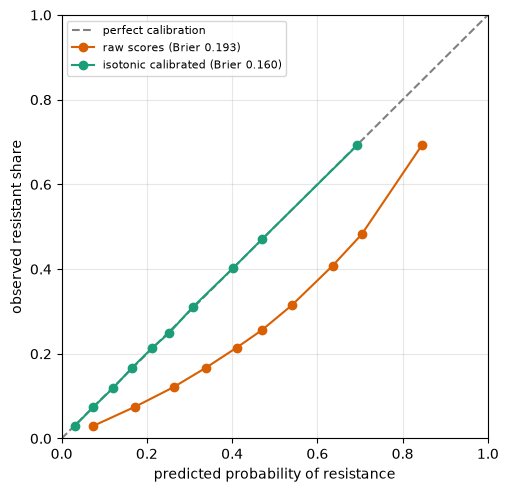

In [14]:
import matplotlib.pyplot as plt
before = metrics.calibration_curve_points(y_test, test_raw)
after = metrics.calibration_curve_points(y_test, test_score)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], '--', color='grey', label='perfect calibration')
ax.plot([p['predicted'] for p in before if p['n']], [p['observed'] for p in before if p['n']], 'o-', color='#d95f02',
        label=f"raw scores (Brier {raw['brier']:.3f})")
ax.plot([p['predicted'] for p in after if p['n']], [p['observed'] for p in after if p['n']], 'o-', color='#1b9e77',
        label=f"isotonic calibrated (Brier {result['brier']:.3f})")
ax.set_xlabel('predicted probability of resistance'); ax.set_ylabel('observed resistant share')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
plt.show()

## 10. The weakest antibiotics, and how the website uses the model

In [15]:
by_drug = metrics.per_group(y_test, test_score, test_rows['Antibiotic'].to_numpy(), threshold, min_n=1000)
pd.DataFrame(by_drug)[['group', 'n', 'prevalence', 'auc_roc']].head(8).round(3)

,group,n,prevalence,auc_roc
0,prothionamide,9226,0.311,0.503
1,norfloxacin,23060,0.292,0.503
2,nicotinamide,9226,0.184,0.504
3,doxycycline,23180,0.580,0.505
4,trimethoprim/sulfobactam,1590,0.584,0.506
5,cephalothin,23017,0.252,0.511
6,amoxicillin,23258,0.453,0.514
7,cycloserine,9229,0.062,0.520


The website loads the promoted copy of this model from `backend/trained_models/` with `backend/ml_models/lgbm_predictor.py`, which builds the same 14 features from a user's form. One prediction through that code:

In [16]:
sys.path.insert(0, os.path.join(ROOT, 'backend'))
from ml_models.lgbm_predictor import LGBMResistancePredictor
served = LGBMResistancePredictor(os.path.join(ROOT, 'backend', 'trained_models'))
r = served.predict('ciprofloxacin', taxon_id=562, mic_value=4, genus='Escherichia', species='coli')
{k: r[k] for k in ['prediction', 'probability', 'threshold', 'model_run', 'calibrated']}

[LightGBM] Model loaded from disk (run D3_forecaster_deploy_v7, taxon level species, calibration isotonic).


{'prediction': 'Resistant',
 'probability': 0.8719,
 'threshold': 0.15,
 'model_run': 'D3_forecaster_deploy_v7',
 'calibrated': True}